# PROYECTO DE ANALÍTICA DE DATOS - MACI 2026
**Alumnos:** 
1. Keyden Urbina P.
2. Christian Hardtmann.
3. Francisco Flores.

**Dataset:** Amazon Products Sales Dataset 2025

**Fuente:** https://www.kaggle.com/datasets/ikramshah512/amazon-products-sales-dataset-42k-items-2025?resource=download

## Etapa 1: Preparación de los datos

#### Paso 1 -- Preparar los datos para el modelo

Qué hace esto:

Deja una fila por producto. Si un producto quedara repetido, podría caer a la vez en entrenamiento y en prueba, y el modelo lo “reconocería” en vez de predecirlo.

Excluye los productos con datos faltantes. De los 1.536 excluidos, la mayoría son 1.124 que no tienen dato de compras, y no se pueden etiquetar. Otros 427 no tienen precio y 66 no tienen reseñas ni rating; algunos productos caen en más de un grupo.

Construye `X` e `Y`:

`X` son las tres variables de entrada. Reseñas y precio van en logaritmo base 10 para que los valores extremos no dominen: un valor de 3 equivale a 1.000 reseñas y uno de 2 a US$ 100.

`Y` vale 1 si el producto tiene 400 o más compras al mes y 0 si tiene menos.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = pd.read_csv(BASE / "data" / "procesado" / "amazon_electronics_cleaned_with_asin.csv", parse_dates=["data_collected_at"])

# 1. Una fila por producto: la última captura de cada ASIN
productos = datos.sort_values("data_collected_at")
productos = productos[productos["asin"].isna() | ~productos.duplicated("asin", keep="last")]

# 2. Solo productos con las 4 variables (sin dato de compras NO significa baja demanda: se excluyen)
VARIABLES = ["total_reviews", "original_price", "product_rating", "purchased_last_month"]
print("Productos sin dato, por variable:", productos[VARIABLES].isna().sum().to_dict())
modelo = productos.dropna(subset=VARIABLES)

# 3. Variables de entrada X (reseñas y precio en logaritmo) y variable objetivo y
UMBRAL = 400                                                    # mediana de compras del último mes, fija
X = pd.DataFrame({"log_reseñas": np.log10(modelo["total_reviews"]),
                  "log_precio": np.log10(modelo["original_price"]),
                  "rating": modelo["product_rating"]})
y = (modelo["purchased_last_month"] >= UMBRAL).astype(int).rename("alta_demanda")

print(f"Productos: {len(productos):,} | con las 4 variables: {len(modelo):,} | excluidos: {len(productos) - len(modelo):,}")
print(pd.DataFrame({"productos": y.value_counts(), "%": y.value_counts(normalize=True).mul(100).round(1)})
      .rename(index={1: "alta demanda (1)", 0: "baja demanda (0)"}))
X.describe().round(2)

Productos sin dato, por variable: {'total_reviews': 66, 'original_price': 427, 'product_rating': 66, 'purchased_last_month': 1124}
Productos: 8,825 | con las 4 variables: 7,289 | excluidos: 1,536
                  productos     %
alta_demanda                     
alta demanda (1)       3885  53.3
baja demanda (0)       3404  46.7


,log_reseñas,log_precio,rating
count,7289.00,7289.00,7289.00
mean,2.99,1.93,4.46
std,0.91,0.55,0.27
min,0.00,0.33,2.00
25%,2.39,1.50,4.30
50%,3.01,1.95,4.50
75%,3.62,2.31,4.70
max,5.94,3.63,5.00


### Paso 2 -- Separar entrenamiento (80%) y prueba (20%)

Qué hace:

Separa los productos en dos grupos que no se mezclan:

**Entrenamiento (80%, 5.831 productos):** con estos los modelos aprenden y se ajustan.

**Prueba (20%, 1.458 productos):** quedan guardados y no se tocan hasta el Paso 6. Son el “examen final”: productos que ningún modelo vio antes, y simulan cómo funcionaría con productos nuevos.

`stratify=y` mantiene la proporción de alta demanda (53,3%) en ambos grupos. Sin esto, por azar, la prueba podría quedar con más productos de alta demanda que el entrenamiento, y la comparación no sería justa.

`SEMILLA = 42` fija el azar. Cada vez que corras el notebook, los mismos productos caen en el mismo grupo, así que los resultados son reproducibles. El número 42 es una convención; cualquiera sirve, siempre que no se cambie.

`CV` define la validación cruzada. Dentro del entrenamiento, los modelos se ajustan con 5 particiones:

1. Se entrena con 4/5 de los datos y se evalúa con el 1/5 restante.
2. Se repite 5 veces, rotando qué parte se usa para evaluar.
3. Se promedia el resultado de las 5 rondas.
4. Como `CV` se define una sola vez, los cinco modelos se evalúan sobre exactamente las mismas particiones, y la comparación es justa.


In [2]:
# Paso 2 -- Separar entrenamiento y prueba
from sklearn.model_selection import train_test_split, StratifiedKFold

SEMILLA = 42                                                     # fija el azar: mismos resultados en cada ejecución
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # las 5 particiones que usarán todos los modelos

print(pd.DataFrame({"productos": [len(y_train), len(y_test)],
                    "% alta demanda": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)]},
                   index=["entrenamiento (80%)", "prueba (20%)"]))

                     productos  % alta demanda
entrenamiento (80%)       5831            53.3
prueba (20%)              1458            53.3


## Etapa 2: Modelamiento

### Paso 3 -- Naive Bayes

**Cómo funciona Naive Bayes:** aprende cómo se distribuye cada variable en cada clase. Por ejemplo, cuántas reseñas suele tener un producto de alta demanda y cuántas uno de baja. Ante un producto nuevo, calcula a qué clase es más probable que pertenezca según sus valores. Se llama “naive” (ingenuo) porque asume que las variables son independientes entre sí, aunque no lo sean. Aun así, suele funcionar bien.

**Por qué este modelo va sin escalar:** Naive Bayes trata cada variable por separado, así que la escala no le afecta. Lo que sí necesita es el logaritmo que aplicamos en el Paso 1. Sin él, el AUC cae de 0,82 a 0,76, porque el modelo asume que cada variable tiene forma de campana.

| Métrica | Qué significa | Naive Bayes |
|---|---|---|
| **AUC** | Probabilidad de que el modelo le dé mayor puntaje a un producto de alta demanda que a uno de baja, tomados al azar. 0,5 = azar · 1,0 = perfecto | **0,823** |
| AUC entrenamiento | Lo mismo, pero sobre los datos con que aprendió. Si es mucho mayor que el AUC, el modelo memorizó (sobreajuste) | 0,823 |
| Balanced accuracy | % de aciertos, promediando ambas clases por igual | 0,735 |
| F1 | Equilibrio entre encontrar los productos de alta demanda y no confundirlos con los de baja | 0,758 |
| AUC desv. estándar | Cuánto varía el AUC entre las 5 particiones. Bajo = resultado estable | 0,010 |

In [3]:
# Paso 3 -- Modelo base: Naive Bayes
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB

METRICAS = ["roc_auc", "balanced_accuracy", "f1"]
resultados = {}                                                  # aquí se acumula el desempeño de cada modelo

def evaluar(nombre, modelo):
    "Validación cruzada sobre el entrenamiento (mismas 5 particiones para todos los modelos)."
    r = cross_validate(modelo, X_train, y_train, cv=CV, scoring=METRICAS, return_train_score=True)
    resultados[nombre] = {"AUC": r["test_roc_auc"].mean(), "AUC entrenamiento": r["train_roc_auc"].mean(),
                          "Balanced accuracy": r["test_balanced_accuracy"].mean(), "F1": r["test_f1"].mean(),
                          "AUC desv. estándar": r["test_roc_auc"].std()}
    return pd.DataFrame(resultados).T.round(3)

evaluar("Naive Bayes", GaussianNB())

,AUC,AUC entrenamiento,Balanced accuracy,F1,AUC desv. estándar
Naive Bayes,0.823,0.823,0.735,0.758,0.01


**Discrimina bien:** con un AUC de 0,823, en 82 de cada 100 pares (un producto de alta demanda y uno de baja), el modelo asigna más puntaje al de alta.

**No sobreajusta:** el AUC de entrenamiento y el de validación son iguales (0,823). Es lo esperable en un modelo tan simple.

**Es estable:** varía solo ±0,01 entre particiones.

Esta es la vara a superar. Si un modelo más complejo no pasa de 0,823, su complejidad no se justifica.

In [4]:
nb = GaussianNB().fit(X_train, y_train)
pd.DataFrame(nb.theta_, columns=X.columns, index=["baja demanda", "alta demanda"]).round(2)

,log_reseñas,log_precio,rating
baja demanda,2.51,2.21,4.40
alta demanda,3.41,1.70,4.51


Un producto típico de alta demanda tiene unas 8 veces más reseñas y cuesta un tercio que uno de baja. El rating apenas cambia entre clases, igual que vimos en la exploración.

### Paso 4 -- K vecinos más cercanos (KNN)

Cómo funciona KNN

Para clasificar un producto nuevo, KNN busca los k productos más parecidos del entrenamiento: los más cercanos en reseñas, precio y rating. Luego mira cuántos de ellos son de alta demanda. Si de 201 vecinos 150 son de alta demanda, el producto nuevo recibe una probabilidad de 150/201 = 75% de ser de alta demanda.

No aprende ninguna fórmula: memoriza los datos y compara. Por eso dos cosas son críticas.

1. Escalar las variables (StandardScaler). KNN mide distancias entre productos. Si no se escala, las variables con números más grandes dominan la distancia y las otras casi no cuentan. StandardScaler deja las tres variables en la misma escala (promedio 0, desviación 1), para que pesen lo mismo. Va dentro del pipeline para que el escalado se calcule solo con el entrenamiento de cada partición y no se filtre información de validación.

2. Elegir k, el hiperparámetro principal. GridSearchCV prueba los 9 valores de k con la validación cruzada del Paso 2 y se queda con el de mejor AUC.

Mejor k: 201 vecinos


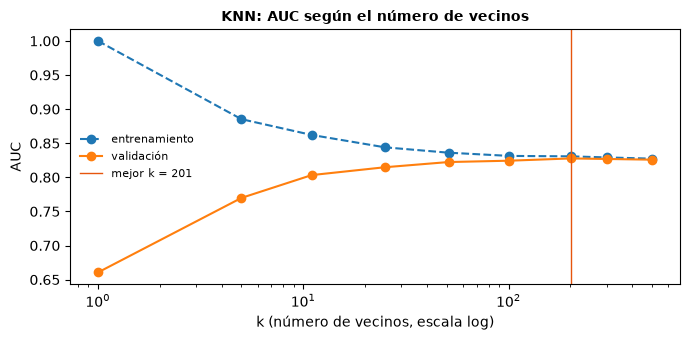

,AUC,AUC entrenamiento,Balanced accuracy,F1,AUC desv. estándar
Naive Bayes,0.823,0.823,0.735,0.758,0.01
KNN (k=201),0.828,0.831,0.746,0.760,0.01


In [5]:
# Paso 4 -- K vecinos más cercanos (KNN)
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn = make_pipeline(StandardScaler(), KNeighborsClassifier())       # escalar dentro del pipeline: se ajusta en cada partición
busqueda_knn = GridSearchCV(knn, {"kneighborsclassifier__n_neighbors": [1, 5, 11, 25, 51, 101, 201, 301, 501]},
                            cv=CV, scoring="roc_auc", return_train_score=True).fit(X_train, y_train)
k_optimo = busqueda_knn.best_params_["kneighborsclassifier__n_neighbors"]
print(f"Mejor k: {k_optimo} vecinos")

# Gráfico: AUC según k, en entrenamiento y validación
cv_knn = pd.DataFrame(busqueda_knn.cv_results_)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv_knn["param_kneighborsclassifier__n_neighbors"], cv_knn["mean_train_score"], "o--", label="entrenamiento")
ax.plot(cv_knn["param_kneighborsclassifier__n_neighbors"], cv_knn["mean_test_score"], "o-", label="validación")
ax.axvline(k_optimo, color="#e6550d", lw=1, label=f"mejor k = {k_optimo}")
ax.set(xscale="log", xlabel="k (número de vecinos, escala log)", ylabel="AUC")
ax.set_title("KNN: AUC según el número de vecinos", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

evaluar(f"KNN (k={k_optimo})", busqueda_knn.best_estimator_)

| k | AUC entrenamiento | AUC validación | Lectura |
|---:|---:|---:|---|
| 1 | **1,000** | **0,660** | Sobreajuste extremo: cada producto es su propio vecino. En entrenamiento acierta todo, pero falla con productos nuevos |
| 11 | 0,862 | 0,803 | Mejora, aunque todavía hay una brecha grande |
| 51 | 0,836 | 0,822 | Las curvas casi se juntan |
| **201** | 0,831 | **0,828** | Mejor resultado: la brecha es mínima |
| 501 | 0,827 | 0,826 | Empieza a bajar levemente: con demasiados vecinos se "diluye" la información |

Este es el dilema sesgo-varianza en un solo gráfico:

Con k pequeño el modelo es demasiado sensible a cada producto: memoriza.
Con k grande el modelo suaviza y generaliza mejor.
Desde k ≈ 50 la mejora es mínima: de 0,822 a 0,828.

Que el mejor k sea tan alto (201) indica que el patrón es simple y gradual: no hay “islas” de productos de alta demanda, sino una tendencia continua del tipo “más reseñas y menor precio, más demanda”.

KNN supera levemente a Naive Bayes (+0,005 en AUC), sin sobreajuste. La diferencia es pequeña: ambos captan el mismo patrón.

### Paso 5 -- Máquinas de soporte vectorial (SVM)

Cómo funciona SVM

KNN compara cada producto con sus vecinos. SVM, en cambio, traza una frontera que separa los productos de alta demanda de los de baja demanda. Piénsalo como un gráfico de reseñas contra precio, con puntos de dos colores: SVM busca la línea que deja a cada color en su lado con el mayor margen posible.

Margen: la “franja de seguridad” a ambos lados de la línea.

Vectores de soporte: los productos más cercanos a la frontera. Solo ellos definen dónde va la línea; los productos lejanos no la mueven.

Kernel RBF: permite que la frontera sea curva en vez de recta.

| Parámetro | Qué controla | Valor bajo | Valor alto |
|---|---|---|---|
| **gamma** | Cuánto se curva la frontera | Frontera suave, casi recta | Frontera muy curva que "rodea" los productos uno por uno |
| **C** | Cuánto castiga los errores en el entrenamiento | Tolera errores y la frontera queda más simple | No tolera errores y la frontera queda más ajustada |

Mejor gamma: 0.01


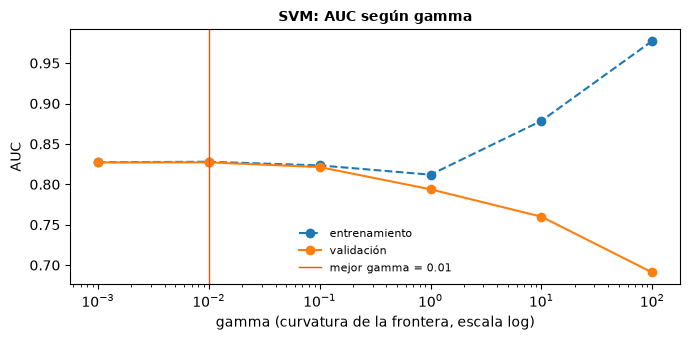

,AUC,AUC entrenamiento,Balanced accuracy,F1,AUC desv. estándar
Naive Bayes,0.823,0.823,0.735,0.758,0.01
KNN (k=201),0.828,0.831,0.746,0.760,0.01
SVM (gamma=0.01),0.827,0.828,0.739,0.757,0.01


In [6]:
# Paso 5 -- Máquinas de soporte vectorial (SVM)
from sklearn.svm import SVC

svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1))       # igual que KNN: SVM mide distancias, hay que escalar
busqueda_svm = GridSearchCV(svm, {"svc__gamma": [0.001, 0.01, 0.1, 1, 10, 100]},
                            cv=CV, scoring="roc_auc", return_train_score=True).fit(X_train, y_train)
gamma_optimo = busqueda_svm.best_params_["svc__gamma"]
print(f"Mejor gamma: {gamma_optimo}")

# Gráfico: AUC según gamma, en entrenamiento y validación
cv_svm = pd.DataFrame(busqueda_svm.cv_results_)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv_svm["param_svc__gamma"], cv_svm["mean_train_score"], "o--", label="entrenamiento")
ax.plot(cv_svm["param_svc__gamma"], cv_svm["mean_test_score"], "o-", label="validación")
ax.axvline(gamma_optimo, color="#e6550d", lw=1, label=f"mejor gamma = {gamma_optimo}")
ax.set(xscale="log", xlabel="gamma (curvatura de la frontera, escala log)", ylabel="AUC")
ax.set_title("SVM: AUC según gamma", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

evaluar(f"SVM (gamma={gamma_optimo})", busqueda_svm.best_estimator_)

Hallazgo clave: el mejor gamma es el que deja la frontera casi recta. Lo confirmé probando un SVM con frontera totalmente recta (kernel="linear"): dio el mismo AUC de 0,827. La conclusión es que la separación entre alta y baja demanda es prácticamente lineal: “más reseñas y menor precio → más demanda”, sin formas raras. Es lo mismo que sugería el k = 201 de KNN.

| gamma | AUC entrenamiento | AUC validación | Lectura |
|---:|---:|---:|---|
| 0,001 | 0,827 | 0,827 | Frontera casi recta: no hay sobreajuste |
| **0,01** | 0,828 | **0,827** | Mejor resultado |
| 0,1 | 0,823 | 0,821 | La frontera empieza a curvarse y no mejora |
| 1 | 0,812 | 0,794 | Se abre la brecha entre entrenamiento y validación |
| 10 | 0,879 | 0,760 | Sobreajuste |
| 100 | **0,977** | **0,691** | Sobreajuste extremo: memoriza los productos, igual que KNN con k = 1 |

### Paso 6 -- Árbol de decisión

Cómo funciona un árbol de decisión

Funciona como el juego de las “20 preguntas”. El árbol hace preguntas de sí o no sobre una variable a la vez, por ejemplo “¿tiene más de 1.489 reseñas?”, y en cada paso elige la pregunta que mejor separa la alta de la baja demanda. Al final de cada camino llega a una “hoja” con la clase mayoritaria.

Hay dos diferencias con los modelos anteriores:

No necesita escalar. Cada pregunta mira una sola variable, así que las escalas nunca se mezclan.
Es legible. Entrega reglas que puedes explicarle a cualquier persona del negocio.

El hiperparámetro clave es max_depth, la cantidad máxima de preguntas seguidas.

Mejor profundidad: 5 niveles


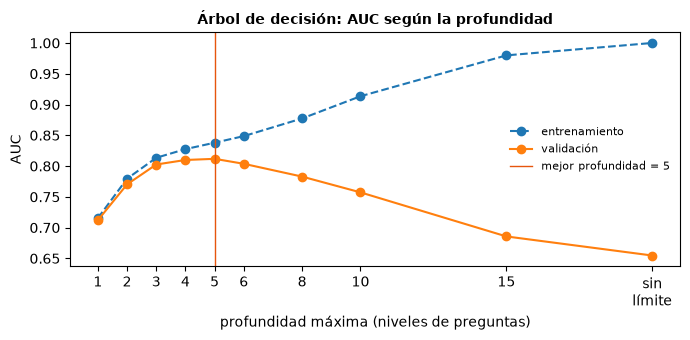

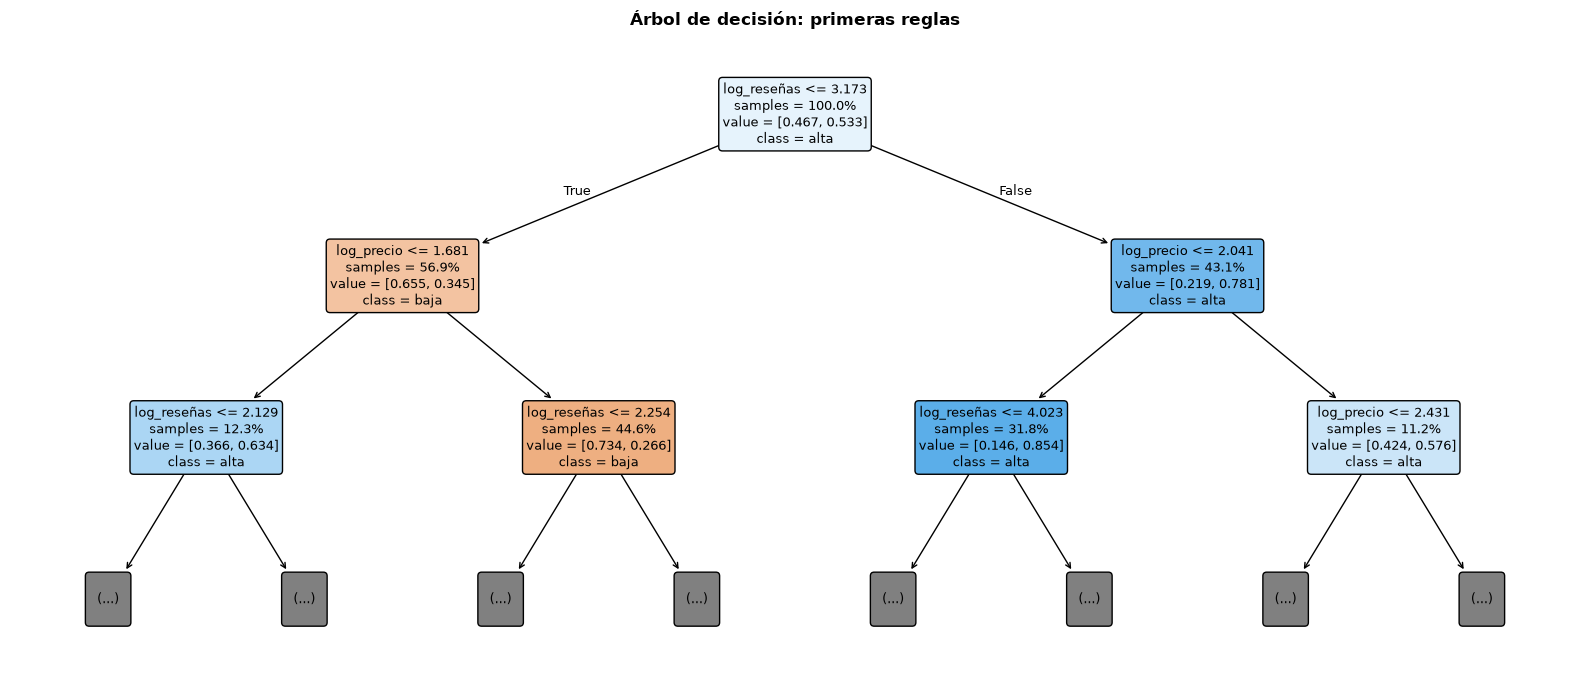

,AUC,AUC entrenamiento,Balanced accuracy,F1,AUC desv. estándar
Naive Bayes,0.823,0.823,0.735,0.758,0.010
KNN (k=201),0.828,0.831,0.746,0.760,0.010
SVM (gamma=0.01),0.827,0.828,0.739,0.757,0.010
Árbol (profundidad=5),0.812,0.838,0.741,0.752,0.015


In [7]:
# Paso 6 -- Árbol de decisión
from sklearn.tree import DecisionTreeClassifier, plot_tree

arbol = DecisionTreeClassifier(random_state=SEMILLA)               # sin escalar: el árbol compara cada variable por separado
busqueda_arbol = GridSearchCV(arbol, {"max_depth": [1, 2, 3, 4, 5, 6, 8, 10, 15, None]},
                              cv=CV, scoring="roc_auc", return_train_score=True).fit(X_train, y_train)
profundidad = busqueda_arbol.best_params_["max_depth"]
print(f"Mejor profundidad: {profundidad} niveles")

# Gráfico 1: AUC según la profundidad, en entrenamiento y validación (None = sin límite, se dibuja en la posición 20)
cv_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
niveles = cv_arbol["param_max_depth"].fillna(20).astype(int)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(niveles, cv_arbol["mean_train_score"], "o--", label="entrenamiento")
ax.plot(niveles, cv_arbol["mean_test_score"], "o-", label="validación")
ax.axvline(profundidad, color="#e6550d", lw=1, label=f"mejor profundidad = {profundidad}")
ax.set_xticks(niveles, [str(n) if n < 20 else "sin\nlímite" for n in niveles])
ax.set(xlabel="profundidad máxima (niveles de preguntas)", ylabel="AUC")
ax.set_title("Árbol de decisión: AUC según la profundidad", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

# Gráfico 2: las reglas del árbol (solo los 2 primeros niveles, para que sea legible)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(busqueda_arbol.best_estimator_, max_depth=2, feature_names=list(X.columns), class_names=["baja", "alta"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Árbol de decisión: primeras reglas", fontweight="bold")
plt.tight_layout()
plt.show()

evaluar(f"Árbol (profundidad={profundidad})", busqueda_arbol.best_estimator_)

| Profundidad | AUC entrenamiento | AUC validación | Lectura |
|---:|---:|---:|---|
| 1 | 0,715 | 0,712 | Una sola pregunta: demasiado simple |
| 3 | 0,813 | 0,803 | Ya capta lo principal |
| **5** | 0,838 | **0,812** | Mejor resultado |
| 8 | 0,877 | 0,783 | Empieza a memorizar |
| 15 | 0,980 | 0,686 | Sobreajuste fuerte |
| Sin límite | **1,000** | **0,654** | Memoriza todo: una hoja por producto |

### Paso 7 -- Random Forest

Cómo funciona Random Forest

Un solo árbol es inestable: si cambias un poco los datos, cambian sus preguntas. Random Forest resuelve eso con “la sabiduría de la multitud”:

Entrena 300 árboles, cada uno con una muestra al azar de los productos (algunos repetidos, otros fuera).
En cada pregunta, cada árbol solo puede elegir entre algunas variables al azar. Así los árboles salen distintos entre sí.
Para clasificar un producto, los 300 árboles votan y el resultado es la proporción de votos. Si 240 votan “alta”, la probabilidad es 80%.

Cada árbol se equivoca de forma distinta, y al promediar, los errores individuales se cancelan. Eso además suaviza los escalones del árbol único.

Mejor profundidad: 6 niveles


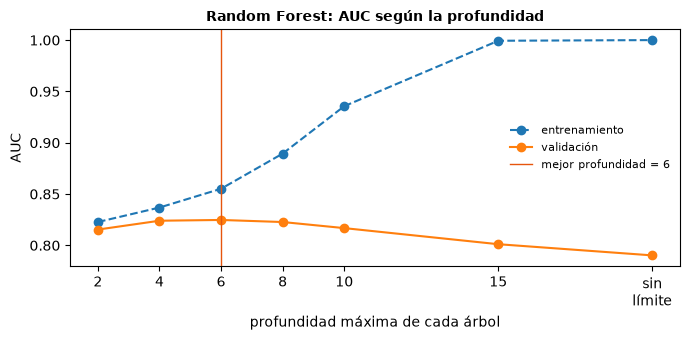

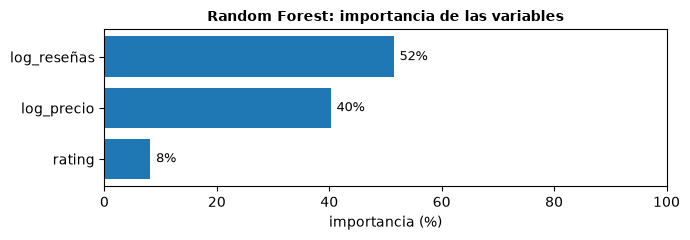

,AUC,AUC entrenamiento,Balanced accuracy,F1,AUC desv. estándar
Naive Bayes,0.823,0.823,0.735,0.758,0.010
KNN (k=201),0.828,0.831,0.746,0.760,0.010
SVM (gamma=0.01),0.827,0.828,0.739,0.757,0.010
Árbol (profundidad=5),0.812,0.838,0.741,0.752,0.015
Random Forest (profundidad=6),0.825,0.855,0.743,0.758,0.011


In [8]:
# Paso 7 -- Random Forest
from sklearn.ensemble import RandomForestClassifier

bosque = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1)   # 300 árboles; n_jobs=-1 usa todos los núcleos
busqueda_bosque = GridSearchCV(bosque, {"max_depth": [2, 4, 6, 8, 10, 15, None]},
                               cv=CV, scoring="roc_auc", return_train_score=True).fit(X_train, y_train)
prof_bosque = busqueda_bosque.best_params_["max_depth"]
print(f"Mejor profundidad: {prof_bosque} niveles")

# Gráfico 1: AUC según la profundidad de los árboles (None = sin límite, se dibuja en la posición 20)
cv_bosque = pd.DataFrame(busqueda_bosque.cv_results_)
niveles = cv_bosque["param_max_depth"].fillna(20).astype(int)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(niveles, cv_bosque["mean_train_score"], "o--", label="entrenamiento")
ax.plot(niveles, cv_bosque["mean_test_score"], "o-", label="validación")
ax.axvline(prof_bosque, color="#e6550d", lw=1, label=f"mejor profundidad = {prof_bosque}")
ax.set_xticks(niveles, [str(n) if n < 20 else "sin\nlímite" for n in niveles])
ax.set(xlabel="profundidad máxima de cada árbol", ylabel="AUC")
ax.set_title("Random Forest: AUC según la profundidad", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

# Gráfico 2: importancia de cada variable en el bosque
importancia = pd.Series(busqueda_bosque.best_estimator_.feature_importances_, X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.barh(importancia.index, importancia * 100, color="#1f77b4")
for i, v in enumerate(importancia * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set(xlabel="importancia (%)", xlim=(0, 100))
ax.set_title("Random Forest: importancia de las variables", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.show()

evaluar(f"Random Forest (profundidad={prof_bosque})", busqueda_bosque.best_estimator_)

| Profundidad | AUC entrenamiento | AUC validación | Lectura |
|---:|---:|---:|---|
| 2 | 0,823 | 0,815 | Árboles muy simples |
| 4 | 0,837 | 0,824 | Casi el máximo, con brecha baja (0,013) |
| **6** | 0,855 | **0,825** | Mejor resultado |
| 10 | 0,936 | 0,817 | Empieza a memorizar |
| Sin límite | **1,000** | **0,790** | Memoriza, pero cae mucho menos que el árbol solo |

| Sin límite de profundidad | AUC validación |
|---|---:|
| Árbol de decisión (1 árbol) | 0,654 |
| Random Forest (300 árboles) | 0,790 |

Los dos memorizan el entrenamiento (AUC 1,000), pero el promedio de 300 árboles rescata +0,136 de AUC. Ese es el efecto de “la multitud”.

Ojo: con profundidad 6 la brecha entre entrenamiento y validación es 0,030, la más alta de los cinco modelos. La profundidad 4 da casi lo mismo (0,824 contra 0,825) con menos de la mitad de brecha. Si tu profesor valora la parsimonia, la profundidad 4 es defendible.

| Variable | Árbol de decisión | Random Forest |
|---|---:|---:|
| Reseñas | 68% | 52% |
| Precio | 29% | 40% |
| Rating | 2% | 8% |

Random Forest mejora al árbol solo (+0,013) y se mete en el grupo de arriba. Pero no supera a KNN ni a SVM, porque el patrón es casi lineal y los modelos más complejos no tienen nada extra que capturar.

Lectura de los 5 modelos:

4 de 5 empatan entre 0,823 y 0,828. La diferencia (0,005) es menor que la variación entre particiones (0,010).
Solo el árbol queda claramente atrás.
El techo es de ~0,83 de AUC. Lo ponen las 3 variables, no el algoritmo.

El siguiente paso es la comparación final: elegir el modelo ganador con un criterio explícito y evaluarlo una sola vez en el conjunto de prueba (los 1.458 productos que ningún modelo ha visto todavía), con su matriz de confusión.

### Paso 8 -- Benchmarking

El conjunto de prueba (1.458 productos) se usa una sola vez y solo con el ganador. Si probaras los 5 modelos en la prueba y eligieras el mejor, estarías eligiendo con datos que debían ser “nuevos”. El resultado quedaría inflado y ya no medirías cómo rinde el modelo en el mundo real.

Por eso el orden es:

Elegir el modelo con la validación cruzada.
Reentrenar el ganador con los 5.831 productos de entrenamiento.
Medir una vez en la prueba.

Criterio de selección: el mayor AUC promedio en validación cruzada. El ganador es KNN (k=201), con 0,828.

Modelo ganador (mayor AUC en validación cruzada): KNN (k=201)


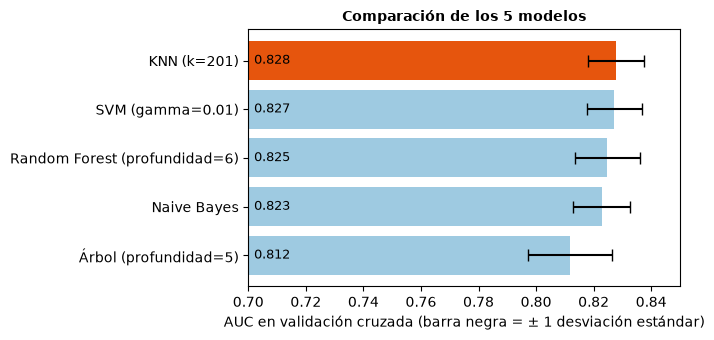

,Validación cruzada,Prueba
AUC,0.828,0.833
Balanced accuracy,0.746,0.743
F1,0.760,0.757


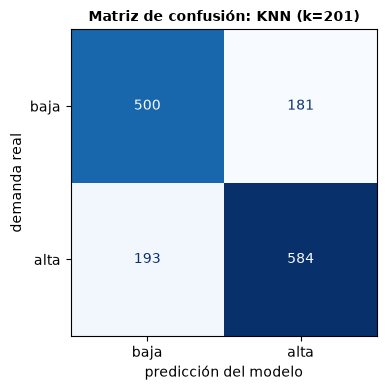

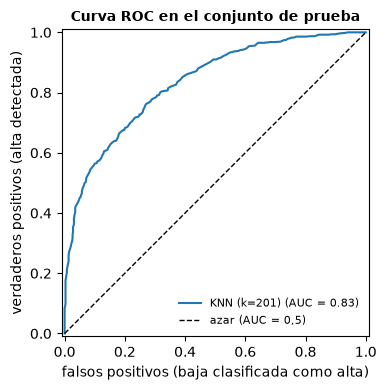

In [10]:
# Paso 8 -- Comparación de los 5 modelos y evaluación final en el conjunto de prueba
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, ConfusionMatrixDisplay, RocCurveDisplay

# 1. Elegir el ganador SOLO con la validación cruzada (el conjunto de prueba todavía no se toca)
modelos = {"Naive Bayes": GaussianNB(),
           f"KNN (k={k_optimo})": busqueda_knn.best_estimator_,
           f"SVM (gamma={gamma_optimo})": busqueda_svm.best_estimator_,
           f"Árbol (profundidad={profundidad})": busqueda_arbol.best_estimator_,
           f"Random Forest (profundidad={prof_bosque})": busqueda_bosque.best_estimator_}
tabla = pd.DataFrame(resultados).T.loc[list(modelos)]
ganador = tabla["AUC"].idxmax()
print(f"Modelo ganador (mayor AUC en validación cruzada): {ganador}")

# Gráfico 1: AUC de validación de cada modelo, con su variación entre particiones
orden = tabla.sort_values("AUC")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(orden.index, orden["AUC"], xerr=orden["AUC desv. estándar"], capsize=4,
        color=["#e6550d" if m == ganador else "#9ecae1" for m in orden.index])
for i, v in enumerate(orden["AUC"]):
    ax.text(0.702, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(xlim=(0.70, 0.85), xlabel="AUC en validación cruzada (barra negra = ± 1 desviación estándar)")
ax.set_title("Comparación de los 5 modelos", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.show()

# 2. Evaluación final: el ganador se entrena con TODO el entrenamiento y se prueba UNA vez con datos nunca vistos
final = modelos[ganador].fit(X_train, y_train)
prob_test = (final.predict_proba(X_test)[:, 1] if hasattr(final, "predict_proba")  # probabilidad de alta demanda
             else final.decision_function(X_test))                 # (SVM no da probabilidad: entrega un puntaje)
pred_test = final.predict(X_test)                                 # clase final (corte en 50%)
prueba = pd.Series({"AUC": roc_auc_score(y_test, prob_test),
                    "Balanced accuracy": balanced_accuracy_score(y_test, pred_test),
                    "F1": f1_score(y_test, pred_test)})
display(pd.DataFrame({"Validación cruzada": tabla.loc[ganador, prueba.index], "Prueba": prueba}).round(3))

# Gráfico 2: matriz de confusión en el conjunto de prueba
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["baja", "alta"], cmap="Blues", colorbar=False, ax=ax)
ax.set(xlabel="predicción del modelo", ylabel="demanda real")
ax.set_title(f"Matriz de confusión: {ganador}", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.show()

# Gráfico 3: curva ROC en el conjunto de prueba
fig, ax = plt.subplots(figsize=(4.5, 4))
RocCurveDisplay.from_predictions(y_test, prob_test, name=ganador, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="azar (AUC = 0,5)")
ax.set(xlabel="falsos positivos (baja clasificada como alta)", ylabel="verdaderos positivos (alta detectada)")
ax.set_title("Curva ROC en el conjunto de prueba", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

#### Comparativo de resultados:

| Modelo | AUC validación | ± desv. estándar | Rango (AUC ± desv.) |
|---|---:|---:|---|
| **KNN (k=201)** | **0,828** | 0,010 | 0,818 – 0,838 |
| SVM (gamma=0,01) | 0,827 | 0,010 | 0,817 – 0,837 |
| Random Forest (profundidad=6) | 0,825 | 0,011 | 0,814 – 0,836 |
| Naive Bayes | 0,823 | 0,010 | 0,813 – 0,833 |
| Árbol (profundidad=5) | 0,812 | 0,015 | 0,797 – 0,827 |

Las barras negras de los 4 primeros se superponen casi completas, así que en la práctica empatan. KNN gana por margen mínimo. El argumento correcto para la presentación es: “KNN obtuvo el mayor AUC; las diferencias con SVM, Random Forest y Naive Bayes no son relevantes”.

#### Validación cruzada:

| Métrica | Validación cruzada | Prueba |
|---|---:|---:|
| AUC | 0,828 | **0,833** |
| Balanced accuracy | 0,746 | 0,743 |
| F1 | 0,760 | 0,757 |

Esta es la validación más importante del proyecto: con productos nunca vistos, el modelo rinde igual que en la validación cruzada (diferencia ≤ 0,005). Eso significa que no hay sobreajuste y que el 0,83 es una estimación confiable.

#### Matriz de confusión:

| | Predice baja | Predice alta | Total |
|---|---:|---:|---:|
| **Realmente baja** | 500 ✅ | 181 ❌ | 681 |
| **Realmente alta** | 193 ❌ | 584 ✅ | 777 |

En palabras:

Acierta 1.084 de 1.458 productos (74,3%).
Detecta el 75,2% de los productos de alta demanda (584 de 777). Esto se llama recall o sensibilidad.
Cuando dice “alta”, acierta el 76,3% de las veces (584 de 765). Esto se llama precisión.
Los errores están equilibrados (181 contra 193), así que el modelo no está sesgado hacia ninguna clase.

#### Curva ROC

La curva muestra el balance entre detectar productos de alta demanda (eje vertical) y equivocarse con los de baja (eje horizontal), para todos los cortes posibles. La diagonal punteada es adivinar al azar.

Cómo leer un AUC de 0,83: si tomas al azar un producto de alta demanda y uno de baja, el modelo le asigna mayor probabilidad al de alta en el 83% de los casos. Al azar sería 50%.

#### ¿Cuánto aporta cada variable? ¿Mejoraría el modelo con más variables?

In [11]:
# Paso 9 -- ¿Cuánto aporta cada variable? ¿Mejoraría el modelo con más variables?
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

def auc_cv(columnas, modelo_base=modelos[ganador]):
    "AUC en validación cruzada usando solo las columnas indicadas (por defecto, con el modelo ganador)."
    return cross_val_score(clone(modelo_base), columnas.loc[X_train.index], y_train, cv=CV, scoring="roc_auc").mean()

# 1. Quitar una variable a la vez: cuánto cae el AUC sin ella = cuánto aporta
auc_base = auc_cv(X)
aporte = pd.Series({v: auc_base - auc_cv(X.drop(columns=v)) for v in X.columns}, name="AUC que se pierde sin ella")
display(aporte.sort_values(ascending=False).round(3).to_frame())

# 2. Agregar las demás variables comerciales del dataset (con Random Forest, que maneja bien muchas variables)
X_ampliado = pd.concat([X, modelo[["discount_percentage"]].fillna(0),
                        modelo[["is_sponsored", "has_coupon"]].astype(int),
                        pd.get_dummies(modelo["product_category"], prefix="cat", dtype=int)], axis=1)
rf = busqueda_bosque.best_estimator_
print(f"Random Forest | AUC con 3 variables: {auc_cv(X, rf):.3f} | con {X_ampliado.shape[1]} variables "
      f"(+ descuento, patrocinio, cupón y categoría): {auc_cv(X_ampliado, rf):.3f}")

,AUC que se pierde sin ella
log_reseñas,0.062
log_precio,0.034
rating,0.002


Random Forest | AUC con 3 variables: 0.825 | con 27 variables (+ descuento, patrocinio, cupón y categoría): 0.832


Quita una variable a la vez. Lo que cae el AUC sin ella es lo que esa variable aporta.
Agrega las demás variables del dataset. Así se ve si el techo de 0,83 se debe a que usamos pocas variables.

Detalle técnico: para la segunda prueba se usa Random Forest y no KNN. Lo probé con KNN y el AUC baja a 0,774. Con 27 variables, las 21 columnas de categoría dominan la distancia entre productos y “tapan” las reseñas y el precio. A esto se le llama la maldición de la dimensionalidad.

### Paso 9 -- Conclusiones del Modelamiento

¿Qué diferencia a un producto de alta demanda?

| Variable | Perfil alta demanda | Perfil baja demanda | AUC que se pierde sin ella | Importancia (Random Forest) |
|---|---:|---:|---:|---:|
| **Reseñas** | ~2.570 | ~320 | **0,061** | 52% |
| **Precio** | ~US$50 | ~US$162 | **0,034** | 40% |
| Rating | 4,51 | 4,40 | 0,002 | 8% |

1. Las reseñas son la variable principal. Un producto de alta demanda tiene 8 veces más reseñas. Si se quitan, el AUC cae de 0,828 a 0,767.

2. El precio es la segunda. La relación es inversa: los productos de alta demanda cuestan un tercio de lo que cuestan los de baja.

3. El rating prácticamente no aporta. Sin él, el AUC baja solo 0,002. Casi todos los productos están entre 4,3 y 4,6 estrellas, así que el rating no distingue entre unos y otros.

Regla de Negocio:

| Perfil | % de productos | % de alta demanda |
|---|---:|---:|
| Más de 1.489 reseñas y precio ≤ US$110 | 31,8% | **85,4%** |
| Hasta 1.489 reseñas y precio > US$48 | 44,6% | 26,6% |

¿Qué tan bien clasifica el modelo?

| Resultado | Valor |
|---|---|
| Modelo ganador | KNN (k=201) |
| AUC en el conjunto de prueba | **0,833** |
| Productos bien clasificados | 74,3% (1.084 de 1.458) |
| Alta demanda detectada (recall) | 75,2% |
| Diferencia validación vs. prueba | ≤ 0,005 → no hay sobreajuste |

El techo esta en los datos y no en el algoritmo:
| Prueba | AUC |
|---|---:|
| Random Forest con 3 variables | 0,825 |
| Random Forest con 27 variables (+ descuento, patrocinio, cupón, categoría) | 0,832 |
| **Ganancia** | **+0,007** |

Agregar todo lo que tiene el dataset sube el AUC menos que la variación normal entre particiones (0,010). Para pasar de 0,83 no sirve otro algoritmo ni más columnas de este dataset: hacen falta datos distintos.

Limitaciones:
| Limitación | Por qué importa |
|---|---|
| **Causalidad inversa en las reseñas** | Las reseñas son en parte *consecuencia* de vender: quien compra, reseña. El modelo muestra asociación, no causa. "Conseguir reseñas" no garantiza vender más |
| **Compras reportadas en tramos** | Amazon publica 50, 100, 200 … 1.000, 2.000. No hay valores intermedios, y 512 productos (7%) quedan justo en 400, en el borde del umbral |
| **1.124 productos sin dato de compras (12,7%)** | Fueron excluidos. Si Amazon oculta el dato a los productos que venden poco, el modelo nunca vio a los de menor demanda |
| **10 días de captura (21–30 ago 2025)** | Es una foto, no una tendencia. No capta estacionalidad (Black Friday, Navidad) |
| **Solo electrónica** | No se puede extrapolar a otras categorías de Amazon |

In [12]:
# Paso 12 -- Análisis de sensibilidad: ¿cambia la conclusión si los productos sin dato de compras se cuentan como baja demanda?
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = pd.read_csv(BASE / "data" / "procesado" / "amazon_electronics_cleaned_with_asin.csv", parse_dates=["data_collected_at"])
productos = datos.sort_values("data_collected_at")
productos = productos[productos["asin"].isna() | ~productos.duplicated("asin", keep="last")]   # 1 fila por producto
con_x = productos.dropna(subset=["total_reviews", "original_price", "product_rating"])           # tienen las 3 variables X

escenarios = {   # nombre: productos usados
    "Base: solo productos con dato de compras": con_x[con_x["purchased_last_month"].notna()],
    "Sensibilidad: sin dato de compras = baja demanda": con_x}

SEMILLA = 42
filas = {}
for nombre, d in escenarios.items():
    X = pd.DataFrame({"log_reseñas": np.log10(d["total_reviews"]), "log_precio": np.log10(d["original_price"]),
                      "rating": d["product_rating"]})
    y = (d["purchased_last_month"].fillna(0) >= 400).astype(int)          # NaN -> 0 -> baja demanda
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=201))
    prob = lambda cols: knn.fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]
    auc = lambda cols: roc_auc_score(y_test, prob(cols))
    p3, pr = prob(list(X.columns)), prob(["log_reseñas"])
    auc_3, auc_r = roc_auc_score(y_test, p3), roc_auc_score(y_test, pr)
    rng = np.random.default_rng(SEMILLA)                                   # misma prueba bootstrap del Paso 10
    dif = [roc_auc_score(y_test.iloc[i], p3[i]) - roc_auc_score(y_test.iloc[i], pr[i])
           for i in (rng.integers(0, len(y_test), len(y_test)) for _ in range(2000))]
    filas[nombre] = {"Productos": len(d), "% del total": len(d) / len(productos) * 100, "% alta demanda": y.mean() * 100,
                     "AUC solo reseñas": auc_r, "AUC reseñas + precio + rating": auc_3, "Mejora": auc_3 - auc_r,
                     "IC 95% inferior": np.percentile(dif, 2.5), "valor p": np.mean(np.array(dif) <= 0),
                     "AUC sin precio": auc(["log_reseñas", "rating"]), "AUC sin rating": auc(["log_reseñas", "log_precio"])}
display(pd.DataFrame(filas).T.round(3))

,Productos,% del total,% alta demanda,AUC solo reseñas,AUC reseñas + precio + rating,Mejora,IC 95% inferior,valor p,AUC sin precio,AUC sin rating
Base: solo productos con dato de compras,7289.0,82.595,53.299,0.799,0.833,0.034,0.020,0.0,0.799,0.831
Sensibilidad: sin dato de compras = baja demanda,8333.0,94.425,46.622,0.772,0.799,0.027,0.015,0.0,0.783,0.788


| | Base | Sensibilidad |
|---|---:|---:|
| Productos | 7.289 | 8.333 |
| Cobertura del total (8.825) | 82,6% | **94,4%** |
| % alta demanda | 53,3% | 46,6% |
| AUC solo reseñas | 0,799 | 0,772 |
| AUC reseñas + precio + rating | 0,833 | 0,799 |
| **Mejora** | **+0,034** | **+0,027** |
| IC 95% (límite inferior) | +0,020 | +0,015 |
| Valor p | < 0,001 | < 0,001 |
| ¿Se rechaza H₀? | ✅ Sí | ✅ Sí |

Los 492 productos restantes (5,6%) no tienen reseñas, precio o rating, así que ningún escenario puede usarlos.

Interpretación

1. La conclusión principal se mantiene. En los dos escenarios las reseñas son la base, agregar precio y rating mejora significativamente (p < 0,001) y se rechaza H₀. Puedes decir con seguridad: “la conclusión no depende de haber excluido los productos sin dato de compras”.

2. El AUC baja (de 0,833 a 0,799). Es esperable, no es un problema. Algunos de los productos sin dato seguramente sí venden bien. Al forzarlos a “baja demanda” se mete ruido en las etiquetas, y el modelo pierde precisión porque los datos son más confusos, no porque el patrón cambie.

| AUC que se pierde al quitar... | Base | Sensibilidad |
|---|---:|---:|
| El precio | 0,034 | 0,016 |
| El rating | 0,002 | **0,011** |

Al incluir los productos sin dato de compras, el rating pasa de aportar casi nada a aportar algo. La lectura probable: entre los productos que Amazon no destaca hay más productos con peor calificación, y el rating ayuda a separarlos. Vale la pena mencionarlo en la defensa como hallazgo secundario. No cambia la decisión de la app, que usa el escenario base (el validado).

| Etapa | Cantidad | Qué se perdió y por qué |
|---|---:|---|
| Filas originales (Kaggle, uncleaned) | 42.675 | — |
| Filas tras la limpieza | 9.472 | −33.203 capturas repetidas del mismo producto |
| Productos únicos (1 fila por producto) | 8.825 | −647 filas: mismo ASIN capturado en fechas distintas |
| Productos modelables | 7.289 | −1.536 sin algún dato clave (1.124 sin compras, 427 sin precio, 66 sin reseñas ni rating) |
| Sensibilidad (sin compras = baja) | 8.333 | Se recuperan 1.044 productos: cobertura 94,4% |